# 1. Problem Definition
   
1.1. Identify the Problem

The goal is to develop a machine learning model capable of distinguishing between text written by humans and text generated by AI models (e.g., ChatGPT, Gemini). This has applications in academic integrity, misinformation detection, content moderation, and authorship verification.


1.2. Define the Machine Learning Objective
This is a binary classification task:

Class 0: Human-written text

Class 1: AI-generated text

1.3. Specify the Output

The model should output either a class label (0 or 1) or a probability score indicating the likelihood that the input text is AI-generated.



##### DataSet Source:
> https://www.kaggle.com/datasets/shanegerami/ai-vs-human-text
>
> https://github.com/rsickle1/human-v-ai

# 2. Exploratory Data Analysis (EDA)

Here, we'll explore the dataset to understand its structure, data types, and distribution of classes.

##### Setup

In [ ]:
pip install --upgrade transformers

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [ ]:
!pip install transformers

In [ ]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 1. Core and Data Manipulation
import pandas as pd
import numpy as np
import time

# 2. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
# Visualization settings
%matplotlib inline
sns.set()

# 3. Natural Language Processing (NLP)
import string
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
# Specific NLTK data path for certain environments (e.g., Kaggle)
# nltk.data.path.append("/kaggle/input/nltk-data/nltk_data")

# 4. Machine Learning (ML) - Feature Extraction and Utilities
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline

# 5. ML Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 6. Performance Metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# 7. Deep Learning / Neural Networks (TensorFlow/Keras)
# Imports typically come from tensorflow.keras
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SimpleRNN, Input
# Direct Keras imports (less common now)
# from keras.layers import SimpleRNN, Embedding, Dense, LSTM
# from keras.models import Sequential

### Importing Data

In [ ]:
df1 = pd.read_csv(r"C:\Users\hp\Desktop\CLA project\5000human_5000machine (1).csv")
df2 = pd.read_csv(r"C:\Users\hp\Desktop\CLA project\AI_Human.csv")

In [ ]:
df1.head()

,index,text,label,source,text_word_count,label_cat,source_int,processed_text
0,47,All the Love you do not see\n\nOn writing with...,0,medium,236,human,0,love see write heart hope photo joshua coleman...
1,85,"Reading, writing and displaying images\n\nBefo...",0,medium,386,human,0,read write display image anything computer vis...
2,255,Why I Think “Target Audience” Doesn’t Always M...,0,medium,323,human,0,think target audience always matter much first...
3,268,"All sorts of books are published every year, a...",0,medium,176,human,0,sort book publish every year sort bookbuyers l...
4,315,Finding The Right Question Not Answer\n\nWhen ...,0,medium,264,human,0,find right question answer face problem one fi...


In [ ]:
df2.head()

,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0


In [ ]:
# Summary statistics of the dataset
df1.describe()

,index,label,text_word_count,source_int
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,171923.678100,0.500000,266.199900,1.434000
std,59703.274397,0.500025,123.808486,1.150555
min,47.000000,0.000000,51.000000,0.000000
25%,150305.750000,0.000000,155.750000,0.000000
50%,205451.500000,0.500000,275.500000,1.500000
75%,210022.500000,1.000000,385.000000,2.000000
max,214728.000000,1.000000,449.000000,3.000000


In [ ]:
df2.describe()

,generated
count,487235.000000
mean,0.372383
std,0.483440
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


### Data Unification and Preparation

In [ ]:
# Standardize AI_Human.csv
# 1. Rename the label column
df2 = df2.rename(columns={'generated': 'label'})

# 2. Select the necessary columns (text and label)
df2 = df2[['text', 'label']]

# 3. Convert the label to integer (0 or 1)
df2['label'] = df2['label'].astype(int)


In [ ]:
# 2. Prepare and Merge the Datasets
#  Prepare 5000human_5000machine.csv
df1_clean = df1[['text', 'label']]

#  Merge the two datasets
unified_df = pd.concat([df1_clean, df2], ignore_index=True)

# Initial Inspection
print("\nUnified Dataset Information:")
print(unified_df.info())

# Save the unified dataset
unified_df.to_csv('unified_df.csv', index=False)
df = pd.read_csv('unified_df.csv')


Unified Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497235 entries, 0 to 497234
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    497235 non-null  object
 1   label   497235 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 7.6+ MB
None


In [ ]:
# Count missing values
missing_counts =df.isna().sum()
print("Number of missing values :\n",missing_counts)

Number of missing values :
 text     0
label    0
dtype: int64


In [ ]:
# Duplicate values Checking
duplicate_rows = df[df.duplicated()]
print("Number of duplicate rows:", duplicate_rows.shape[0])

Number of duplicate rows: 0


Number of AI generated texts vs human text

In [ ]:
# Display class distribution counts and percentages
generated_counts = df['label'].value_counts()
print("Class Distribution Counts:\n",generated_counts)

class_percentage = df['label'].value_counts(normalize=True) * 100
print("Class Distribution Percentages:\n", class_percentage)

Class Distribution Counts:
 label
0    310797
1    186438
Name: count, dtype: int64
Class Distribution Percentages:
 label
0    62.505053
1    37.494947
Name: proportion, dtype: float64


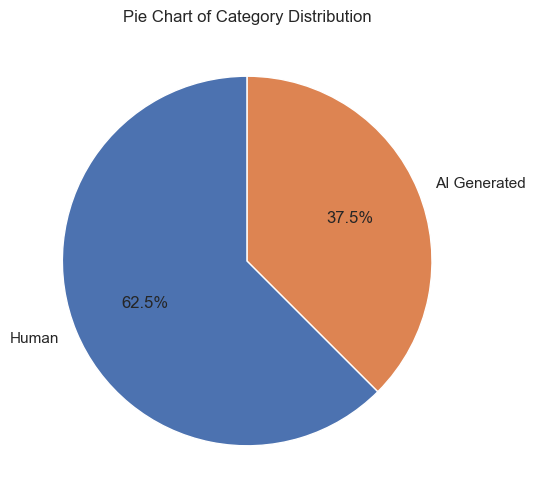

In [ ]:
# Visualize the distribution of the target variable 'generated'/ 'label'
value_counts = df['label'].value_counts()
plt.figure(figsize=(8, 6))
plt.pie(value_counts, labels=['Human','AI Generated'], autopct='%1.1f%%', startangle=90)
plt.title('Pie Chart of Category Distribution')
plt.show()

The majority class (Human) is about $1.67$ times larger than the minority class (Machine).

Check the length of texts

In [ ]:
df['text_length'] = df['text'].apply(lambda x: len(x.split()))
df['text_length'].describe()

count    497235.000000
mean        390.713520
std         168.668143
min           0.000000
25%         276.000000
50%         362.000000
75%         468.000000
max        1668.000000
Name: text_length, dtype: float64

Plot distribution of text lengths by label

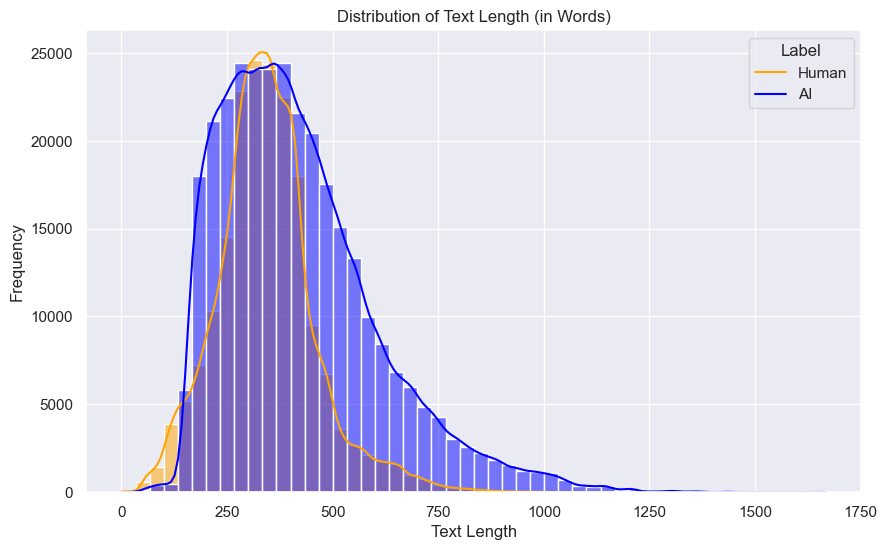

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True, palette={0: 'blue', 1: 'orange'}, fill=True)
plt.title('Distribution of Text Length (in Words)')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.legend(title='Label', labels=['Human', 'AI'])
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_11748\2332793745.py:22: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(human_lengths, kde=True, color='blue', label='Human', ax=axes[1, 2])
C:\Users\hp\AppData\Local\Temp\ipykernel_11748\2332793745.py:23: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ai_le

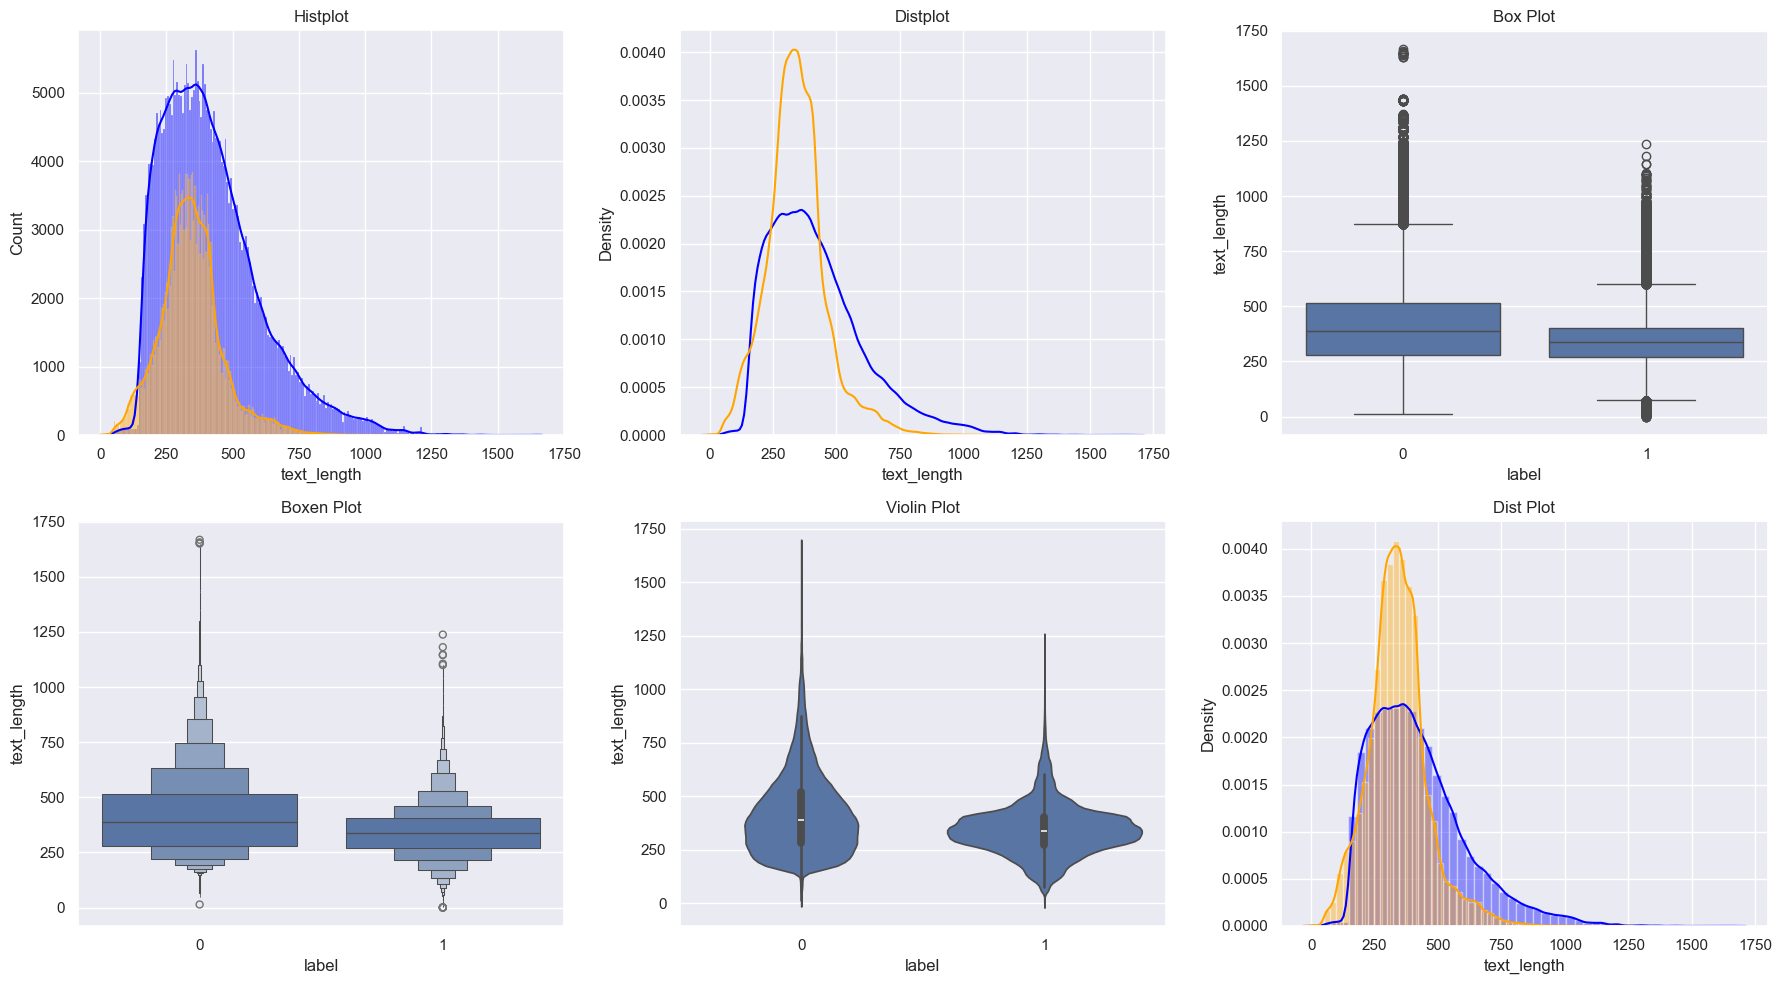

In [ ]:
human_lengths = df[df['label'] == 0]['text_length']
ai_lengths = df[df['label'] == 1]['text_length']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))

sns.histplot(human_lengths, kde=True, color='blue', label='Human', ax=axes[0, 0])
sns.histplot(ai_lengths, kde=True, color='orange', label='AI', ax=axes[0, 0])
axes[0, 0].set_title('Histplot')

sns.kdeplot(human_lengths, color='blue', label='Human', ax=axes[0, 1])
sns.kdeplot(ai_lengths, color='orange', label='AI', ax=axes[0, 1])
axes[0, 1].set_title('Distplot')

sns.boxplot(x='label', y='text_length', data=df, ax=axes[0, 2])
axes[0, 2].set_title('Box Plot')

sns.boxenplot(x='label', y='text_length', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Boxen Plot')

sns.violinplot(x='label', y='text_length', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Violin Plot')

sns.distplot(human_lengths, kde=True, color='blue', label='Human', ax=axes[1, 2])
sns.distplot(ai_lengths, kde=True, color='orange', label='AI', ax=axes[1, 2])
axes[1, 2].set_title('Dist Plot')

plt.tight_layout()
plt.show()

As we can see, the text length distribution is different for human and AI generated texts. Human generated texts tend to be shorter, while AI generated texts tend to be longer. This could be due to the fact that human generated texts are more concise and to the point, while AI generated texts are more verbose and detailed.

The text richness in ai generated text and human ai generated text

In [ ]:
def type_token_ratio(text):
    tokens = text.lower().split()
    return len(set(tokens)) / len(tokens) if len(tokens) > 0 else 0

df['ttr'] = df['text'].apply(type_token_ratio)

# Compare between classes
df.groupby('label')['ttr'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,310797.0,0.482934,0.085241,0.053957,0.425150,0.482609,0.540541,0.932203
1,186438.0,0.511511,0.095301,0.000000,0.445055,0.500000,0.570533,1.000000


AI Text (mean = 0.51) is slightly more lexically rich than human text (mean = 0.48), suggesting more varied vocabulary.
However, overlapping ranges indicate both can have diverse or repetitive language.

In [ ]:
def count_punctuation(text):
    return sum(1 for char in text if char in string.punctuation )

df['punctuation_count'] = df['text'].apply(count_punctuation)

df.groupby('label')['punctuation_count'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,310797.0,49.033231,28.319673,0.0,30.0,44.0,62.0,2581.0
1,186438.0,46.547565,22.893879,0.0,31.0,42.0,58.0,507.0


Human Text (mean = 49) uses slightly more punctuation than AI text (mean = 46.5).

The distribution shows similar variability, but some human texts are far more punctuated (max = 388 vs. 258).

In [ ]:
stop_words = set(stopwords.words('english'))

def stopword_ratio(text):
    tokens = text.lower().split()
    if len(tokens) == 0:
        return 0
    stop_count = sum(1 for token in tokens if token in stop_words)
    return stop_count / len(tokens)

df['stopword_ratio'] = df['text'].apply(stopword_ratio)

df.groupby('label')['stopword_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,310797.0,0.475672,0.054949,0.0,0.443089,0.479201,0.512235,0.724696
1,186438.0,0.433163,0.062392,0.0,0.394521,0.436975,0.475904,0.685039


Human Text (mean = 0.47) has a higher stopword ratio than AI text (mean = 0.43).
This suggests humans use more natural filler words like "the", "and", "is", which AI may underuse.

In [ ]:
def create_wordcloud(data, column, title):
    # Specify a Bangla-supported font, such as "Siyam Rupali"



    #This setting disables the detection of collocations (multi-word phrases) to focus on individual words.
    wordcloud = WordCloud(width=800, height=400, background_color='black', #black
                          colormap='YlGnBu_r', collocations=False).generate(' '.join(data[column]))

    plt.figure(figsize=(8, 4))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'Word Cloud for {column} in {title}', fontsize=16, color='black')
    plt.axis('off')
    plt.show()
df_0 = df[df['label'] == 0].copy()
df_1 = df[df['label'] == 1].copy()

### Wordcloud for AI Content

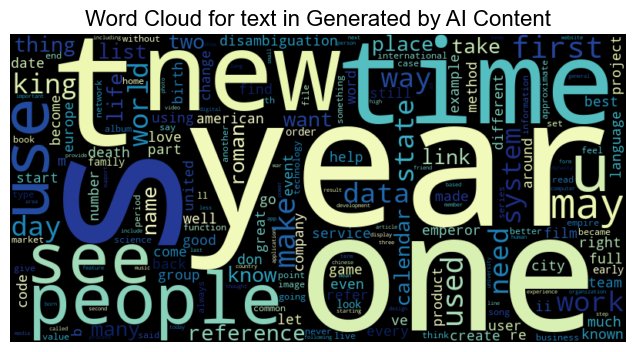

In [ ]:
create_wordcloud(df_0, 'text', 'Generated by AI Content')

### Wordcloud for Human Content

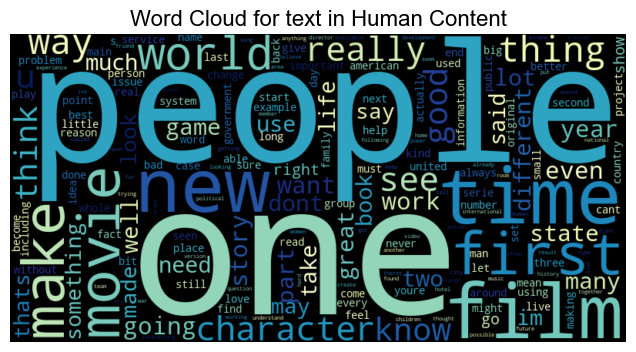

In [ ]:
create_wordcloud(df_1, 'text', 'Human Content')

# 3. Text Preprocessing

In this section, we'll preprocess the text data by cleaning it, removing stopwords, and lemmatizing the words

Filter out and remove normalize text

In [ ]:
df['text'] = df['text'].str.lower() # lower text
df['text'] = df['text'].str.strip().str.replace(r'\s+', ' ', regex=True) # strip the text
df['text'] = df['text'].str.translate(str.maketrans('', '', string.punctuation)) # remove puncituation

Remove Stopwords

In [ ]:
# Define stopwords
stop_words = set(stopwords.words('english'))
df['text'] = df['text'].apply(lambda x: ' '.join(word for word in x.split() if word not in stop_words))

Remove noise like (emails, urls)

In [ ]:
def remove_noise(text):
    text = re.sub(r'http\S+|www\.\S+', '', text)      # URLs
    text = re.sub(r'\S+@\S+\.\S+', '', text)          # Emails
    text = re.sub(r'#[A-Za-z0-9_]+', '', text)        # Hashtags
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)        # Mentions
    text = re.sub(r'\d+', '', text)                   # Numbers
    return ''.join(ch for ch in text if ch.isprintable())  # Non-printable
df['text'] = df['text'].apply(remove_noise)

Remove very short or very long text

Plot before removing

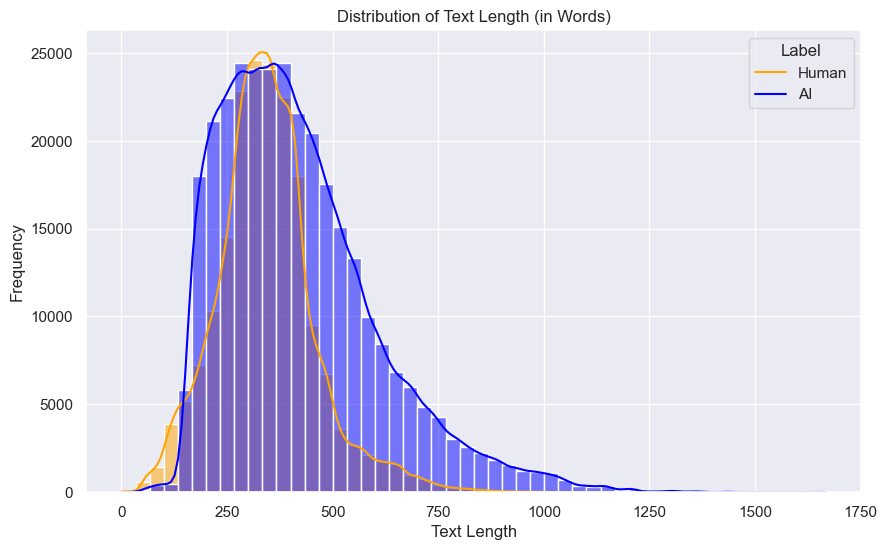

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True, palette={0: 'blue', 1: 'orange'}, fill=True)
plt.title('Distribution of Text Length (in Words)')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.legend(title='Label', labels=['Human', 'AI'])
plt.show()

we will ensure that there is no very long texts and no very short texts to make it easier for us to train the model.

In [ ]:
human_min_words, human_max_words = df[df['label'] == 0 ]['text_length'].quantile([.01, .99])
ai_min_words, ai_max_words = df[df['label'] == 1 ]['text_length'].quantile([.01, .99])

print(human_min_words, human_max_words)
print(ai_min_words, ai_max_words)

157.0 1006.0
97.0 702.0


In [ ]:
# Create masks for each class
human_mask = (df['label'] == 0) & df['text_length'].between(human_min_words, human_max_words)
ai_mask    = (df['label'] == 1) & df['text_length'].between(ai_min_words, ai_max_words)

# Combine masks to filter the DataFrame
df_filtered = df[human_mask | ai_mask].copy()

# Optional: reset index
df_filtered.reset_index(drop=True, inplace=True)

# Show resulting shapes and sample
print("Original dataset shape:", df.shape)
print("Filtered dataset shape:", df_filtered.shape)

df_filtered.head()
df = df.drop_duplicates(subset='text')

Original dataset shape: (497235, 4)
Filtered dataset shape: (487560, 4)


In [ ]:
df_filtered.to_csv('df_filtered.csv', index=False)
df =pd.read_csv('df_filtered.csv')

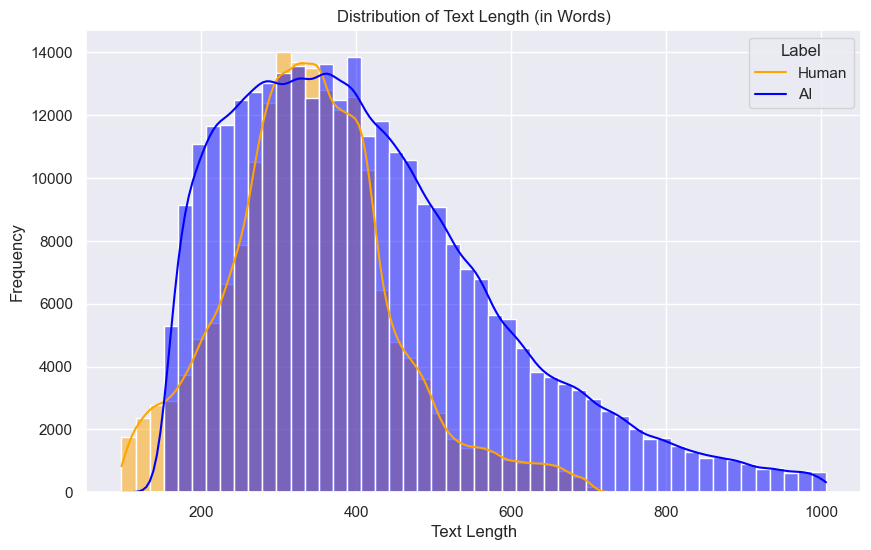

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True, palette={0: 'blue', 1: 'orange'}, fill=True)
plt.title('Distribution of Text Length (in Words)')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.legend(title='Label', labels=['Human', 'AI'])
plt.show()

#  Model Building and Evaluation

##  Machine Learning  Models

In this section, we'll build different models to classify the text and evaluate their performance.

We’ll start with  Naive Bayes (NB) , K-Nearest Neighbors , Decision Tree Logistic Regression (LR)  and Support Vector Machine (SVM). We sampled 10,000 rows from the dataset.

This size is manageable for traditional machine learning models and allows for quick training and evaluation while avoiding long runtimes.

#### For Evaluate Models :
To assess the performance of each model, we define a function that:

Prints the classification report, showing precision, recall, F1-score, and support for each class. Displays the confusion matrix visually, helping us see the counts of true positives, false positives, true negatives, and false negatives. Computes and plots the ROC curve and calculates the AUC (Area Under the Curve) score, which summarizes the model's ability to distinguish between classes. We then apply this evaluation function to each model to compare their effectiveness on the test data.

#### For Comparison : ROC Curve

The ROC (Receiver Operating Characteristic) curve shows the trade-off between the True Positive Rate (TPR) and the False Positive Rate (FPR) at various threshold levels.

This plot compares the performance of all three models:

A higher curve and larger Area Under the Curve (AUC) indicates better classification performance. The diagonal gray line represents a random classifier (AUC = 0.5). This visualization helps us understand which model best distinguishes between spam and not-spam messages

Best Model Based on ROC AUC To determine the best-performing model, we compare the AUC (Area Under the ROC Curve) scores of all classifiers. The model with the highest AUC score is considered the most effective at distinguishing between spam and non-spam messages.

This model will be selected for making final predictions.

In [ ]:
# Sample 10000 rows for ML models
df_zeros = df[df['label'] == 0].head(5000)
df_ones = df[df['label'] == 1].head(5000)
df_new = pd.concat([df_zeros, df_ones], ignore_index=True)
data = df_new


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(
    df['text'], df['label'], test_size=0.25, random_state=58
)

####  Build Machine Learning Pipelines

Training Naive Bayes...
Naive Bayes Trained.

Training KNN...
KNN Trained.

Training Decision Tree...
Decision Tree Trained.

Training Logistic Regression...
Logistic Regression Trained.

Training SVM classifier (this may take a moment)...
SVM Training completed in 144.55 seconds.

--- Naive Bayes Evaluation ---
Naive Bayes Classification Report
              precision    recall  f1-score   support

       Human       0.90      0.72      0.80      1285
          AI       0.76      0.92      0.83      1215

    accuracy                           0.82      2500
   macro avg       0.83      0.82      0.82      2500
weighted avg       0.83      0.82      0.81      2500



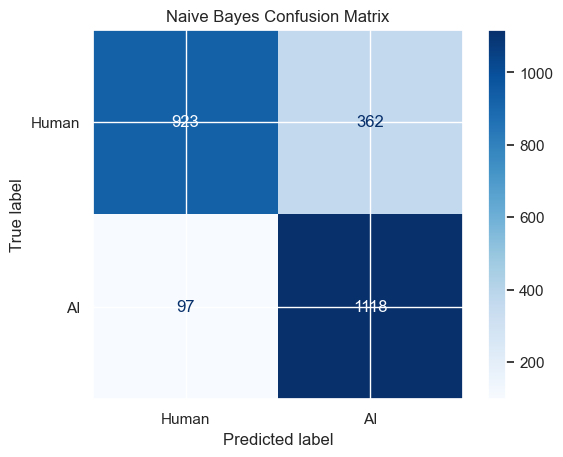

Naive Bayes ROC AUC: 0.9244

--- KNN Evaluation ---
KNN Classification Report
              precision    recall  f1-score   support

       Human       0.86      0.58      0.70      1285
          AI       0.67      0.90      0.77      1215

    accuracy                           0.74      2500
   macro avg       0.77      0.74      0.73      2500
weighted avg       0.77      0.74      0.73      2500



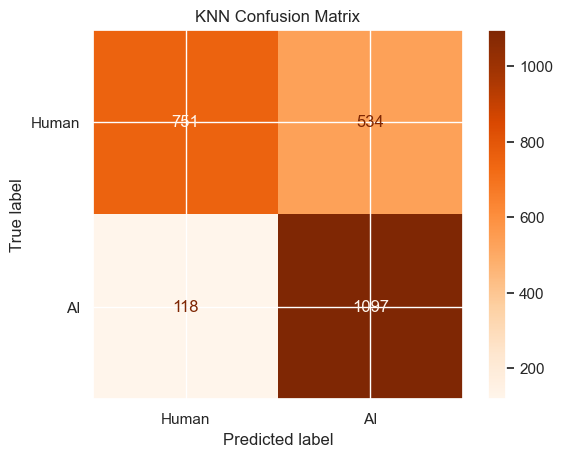

KNN ROC AUC: 0.8494

--- Decision Tree Evaluation ---
Decision Tree Classification Report
              precision    recall  f1-score   support

       Human       0.93      0.68      0.79      1285
          AI       0.74      0.95      0.83      1215

    accuracy                           0.81      2500
   macro avg       0.83      0.81      0.81      2500
weighted avg       0.84      0.81      0.81      2500



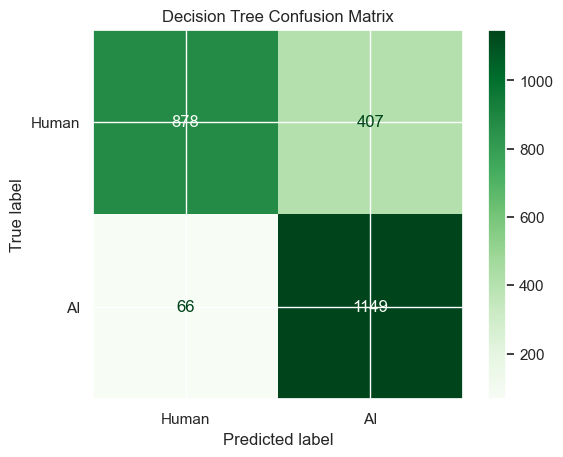

Decision Tree ROC AUC: 0.8582

--- Logistic Regression Evaluation ---
Logistic Regression Classification Report
              precision    recall  f1-score   support

       Human       0.85      0.94      0.89      1285
          AI       0.92      0.83      0.88      1215

    accuracy                           0.88      2500
   macro avg       0.89      0.88      0.88      2500
weighted avg       0.89      0.88      0.88      2500



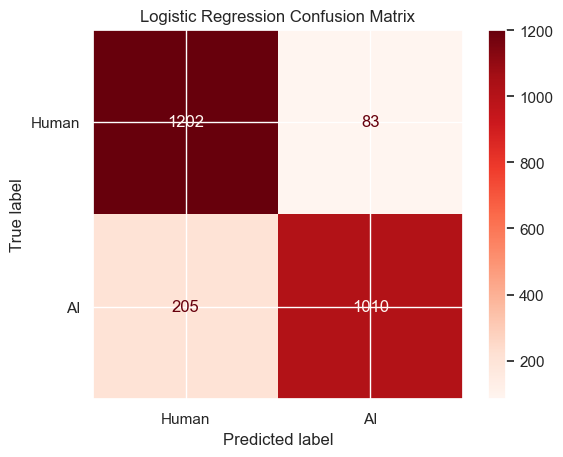

Logistic Regression ROC AUC: 0.9612

--- SVM Evaluation ---
SVM Classification Report
              precision    recall  f1-score   support

       Human       0.89      0.94      0.91      1285
          AI       0.93      0.87      0.90      1215

    accuracy                           0.91      2500
   macro avg       0.91      0.91      0.91      2500
weighted avg       0.91      0.91      0.91      2500



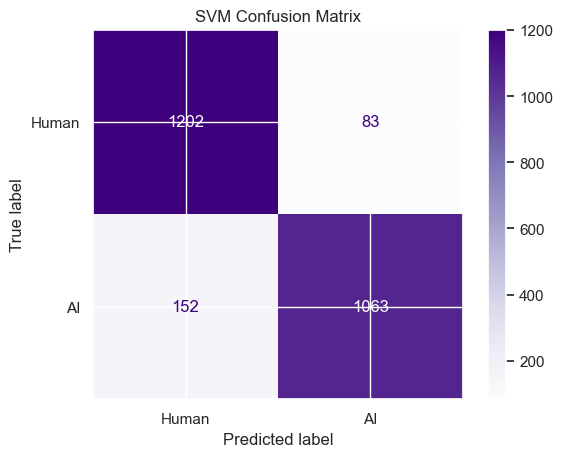

SVM ROC AUC: 0.9731

--- ROC Curve Comparison ---


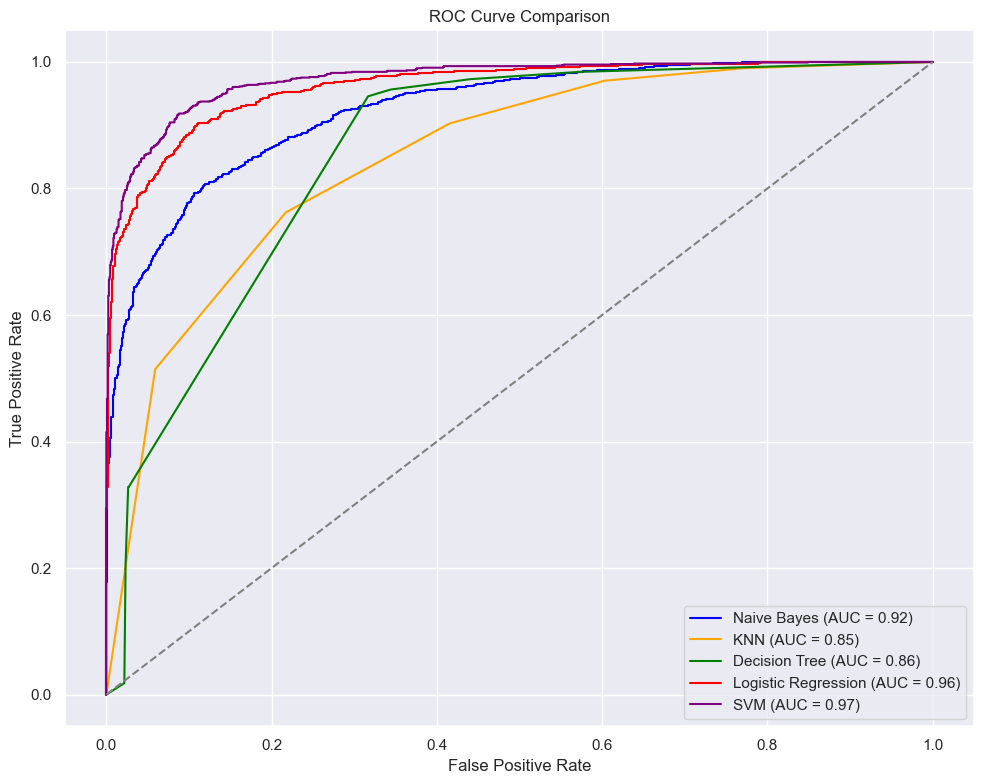


Best Model Based on ROC AUC: SVM (AUC = 0.97)

--- Text Predictions ---

Text 1: Hello Iam  girl , I know u and i want to talk with u so much iam not robot writer 
Naive Bayes: AI
KNN: AI
Decision Tree: AI
Logistic Regression: Human
SVM: AI

Text 2: Reading, writing and displaying images

Befo.
Naive Bayes: AI
KNN: Human
Decision Tree: AI
Logistic Regression: Human
SVM: Human


In [ ]:
# 1. Naive Bayes (NB) Pipeline
nb_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('nb', MultinomialNB())
])
print("Training Naive Bayes...")
nb_pipeline.fit(X_train, Y_train)
nb_preds = nb_pipeline.predict(X_test)
nb_proba = nb_pipeline.predict_proba(X_test)[:, 1]
print("Naive Bayes Trained.")

# 2. K-Nearest Neighbors (KNN) Pipeline
knn_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])
print("\nTraining KNN...")
knn_pipeline.fit(X_train, Y_train)
knn_preds = knn_pipeline.predict(X_test)
knn_proba = knn_pipeline.predict_proba(X_test)[:, 1]
print("KNN Trained.")

# 3. Decision Tree (DT) Pipeline (CART)
dt_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('dt', DecisionTreeClassifier(criterion='gini', random_state=58, max_depth=10))
])
print("\nTraining Decision Tree...")
dt_pipeline.fit(X_train, Y_train)
dt_preds = dt_pipeline.predict(X_test)
dt_proba = dt_pipeline.predict_proba(X_test)[:, 1]
print("Decision Tree Trained.")

# 4. Logistic Regression (LR) Pipeline
lr_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('lr', LogisticRegression(random_state=42, solver='liblinear'))
])
print("\nTraining Logistic Regression...")
lr_pipeline.fit(X_train, Y_train)
lr_preds = lr_pipeline.predict(X_test)
lr_proba = lr_pipeline.predict_proba(X_test)[:, 1]
print("Logistic Regression Trained.")

# 5. Support Vector Machine (SVM) Pipeline
svm_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('svm', SVC(kernel='linear', C=1.0, random_state=42, probability=True))
])
start_time_svm = time.time()
print("\nTraining SVM classifier (this may take a moment)...")
svm_pipeline.fit(X_train, Y_train)
end_time_svm = time.time()
print(f"SVM Training completed in {end_time_svm - start_time_svm:.2f} seconds.")
svm_preds = svm_pipeline.predict(X_test)
svm_proba = svm_pipeline.predict_proba(X_test)[:, 1]


# -Evaluate Models)

def evaluate_model(name, y_true, y_pred, y_proba, cmap):
    """Prints classification metrics and displays Confusion Matrix and ROC AUC."""
    print(f"\n--- {name} Evaluation ---")

    # 1. Classification Report
    print(f"{name} Classification Report")
    print(classification_report(y_true, y_pred, target_names=["Human", "AI"]))

    # 2. Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=["Human", "AI"], cmap=cmap
    )
    plt.title(f"{name} Confusion Matrix")
    plt.show()

    # 3. ROC AUC
    auc = roc_auc_score(y_true, y_proba)
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    print(f"{name} ROC AUC: {auc:.4f}")
    return fpr, tpr, auc

fpr_nb, tpr_nb, auc_nb = evaluate_model("Naive Bayes", Y_test, nb_preds, nb_proba, plt.cm.Blues)
fpr_knn, tpr_knn, auc_knn = evaluate_model("KNN", Y_test, knn_preds, knn_proba, plt.cm.Oranges)
fpr_dt, tpr_dt, auc_dt = evaluate_model("Decision Tree", Y_test, dt_preds, dt_proba, plt.cm.Greens)
fpr_lr, tpr_lr, auc_lr = evaluate_model("Logistic Regression", Y_test, lr_preds, lr_proba, plt.cm.Reds)
fpr_svm, tpr_svm, auc_svm = evaluate_model("SVM", Y_test, svm_preds, svm_proba, plt.cm.Purples)


#  ROC (ROC Curve Comparison) -4

print("\n--- ROC Curve Comparison ---")

plt.figure(figsize=(10, 8))
plt.plot(fpr_nb, tpr_nb, label=f'Naive Bayes (AUC = {auc_nb:.2f})', color='blue')
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn:.2f})', color='orange')
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})', color='green')
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.2f})', color='red')
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.2f})', color='purple')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray') # Random chance line

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


auc_scores = {
    'Naive Bayes': auc_nb,
    'KNN': auc_knn,
    'Decision Tree': auc_dt,
    'Logistic Regression': auc_lr,
    'SVM': auc_svm
}

best_model_name = max(auc_scores, key=auc_scores.get)
print(f"\nBest Model Based on ROC AUC: {best_model_name} (AUC = {auc_scores[best_model_name]:.2f})")


# -Predicting the Classification: Human or AI?)

texts = [
    "Hello Iam  girl , I know u and i want to talk with u so much iam not robot writer ",
    "Reading, writing and displaying images\n\nBefo."
]

print("\n--- Text Predictions ---")
for i, text in enumerate(texts):
    print(f"\nText {i+1}: {text}")

    print("Naive Bayes:", "Human" if nb_pipeline.predict([text])[0] == 0 else "AI")
    print("KNN:", "Human" if knn_pipeline.predict([text])[0] == 0 else "AI")
    print("Decision Tree:", "Human" if dt_pipeline.predict([text])[0] == 0 else "AI")
    print("Logistic Regression:", "Human" if lr_pipeline.predict([text])[0] == 0 else "AI")
    print("SVM:", "Human" if svm_pipeline.predict([text])[0] == 0 else "AI")

#### Analysis of Machine Learning Models
The KNN , SVM and Logistic Regression model are both performing fairly well with accuracy scores over 90%.

We observe that both models might be overfitting slightly due to the relatively high accuracy.

# Neural Network Approach

We’ll use a neural network with  Recurrent Neural Network (RNN) and LSTM layers.

# Simple RNN

In [ ]:
# Sample 10000 rows for DL models
df_zeros = df[df['label'] == 0].head(5000)
df_ones = df[df['label'] == 1].head(5000)
df_new = pd.concat([df_zeros, df_ones], ignore_index=True)
df = df_new

In [ ]:
# Create target
X, y = df['text'], df['label']
texts = np.asarray(X)
labels = np.asarray(y)
print("number of texts :" , len(texts))
print("number of labels: ", len(labels))

number of texts : 10000
number of labels:  10000


In [ ]:
# MODEL HYPERPARAMETERS
#number of words used as features
max_features = 10000
# Maximum length of sequences , Longer sequences will be truncated.
maxlen = 500

# we will use 80% of data as training, 20% as validation data
training_samples = int(total_samples * 0.8)
validation_samples = total_samples - training_samples
# sanity check
print(len(texts) == (training_samples + validation_samples))
print("The number of training {0}, validation {1} ".format(training_samples, validation_samples))



True
The number of training 8000, validation 2000 


## TOKENIZATION AND PADDING

In [ ]:
tokenizer = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

word_index = tokenizer.word_index
print(f"\nFound {len(word_index)} unique words in the entire corpus.")

data = pad_sequences(sequences, maxlen=maxlen)

print(f"Padded data shape: {data.shape}")



Found 93912 unique words in the entire corpus.
Padded data shape: (10000, 500)


In [ ]:
# shuffle data
np.random.seed(42)
indices = np.arange(data.shape[0])
np.random.shuffle(indices)
data = data[indices]
labels = labels[indices]

In [ ]:
# Split the data
texts_train = data[:training_samples]
y_train = labels[:training_samples]
texts_test = data[training_samples:]
y_test = labels[training_samples:]

## MODEL DEFINITION

In [ ]:
# SIMPLE RNN
model = Sequential()
model.add(Embedding(max_features, 32))
# SimpleRNN layer with 32 units
model.add(SimpleRNN(32))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])

print(" Model Training ")
history_rnn = model.fit(
    texts_train,
    y_train,
    epochs=10,
    batch_size=60,
    validation_split=0.2 # Uses 20% of texts_train for validation during training
)


 Model Training 
Epoch 1/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - acc: 0.7120 - loss: 0.5501 - val_acc: 0.8694 - val_loss: 0.3387
Epoch 2/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - acc: 0.9150 - loss: 0.2510 - val_acc: 0.9112 - val_loss: 0.2510
Epoch 3/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 8s 74ms/step - acc: 0.9486 - loss: 0.1609 - val_acc: 0.9075 - val_loss: 0.2773
Epoch 4/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - acc: 0.9772 - loss: 0.0796 - val_acc: 0.8806 - val_loss: 0.3117
Epoch 5/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step - acc: 0.9883 - loss: 0.0476 - val_acc: 0.9100 - val_loss: 0.2748
Epoch 6/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - acc: 0.9941 - loss: 0.0241 - val_acc: 0.9056 - val_loss: 0.2956
Epoch 7/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - acc: 0.9975 - loss: 0.0117 - val_acc: 0.8963 - val_loss: 0.4085
Epoch 8/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - acc: 0.9981 - loss: 0.0079 - val_acc: 0.8794 - val_loss: 0.3950
Epoch 9/10
107/107 ━━━━━━━━━━━

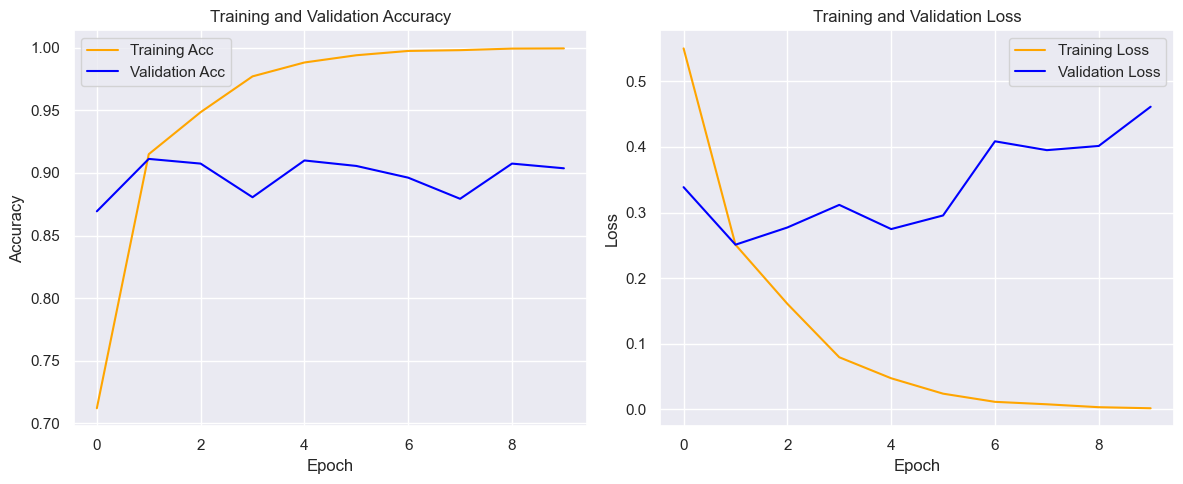

In [ ]:
# PLOTTING RESULTS
acc = history_rnn.history['acc']
val_acc = history_rnn.history['val_acc']
loss = history_rnn.history['loss']
val_loss = history_rnn.history['val_loss']
epochs = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, '-', color='orange', label='Training Acc')
plt.plot(epochs, val_acc, '-', color='blue', label='Validation Acc')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, '-', color='orange', label='Training Loss')
plt.plot(epochs, val_loss, '-', color='blue', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
print("\nFinal Evaluation on Test Set ")
acc = model.evaluate(texts_test, y_test)
pred_proba = model.predict(texts_test)
# Convert probabilities to binary predictions (0 or 1)
pred_classes = (pred_proba > 0.5).astype("int32")

print(f"Test loss is {acc[0]:.4f}, Test accuracy is {acc[1]:.4f}")
print("\nConfusion Matrix:")
# Note: Confusion matrix requires flattened arrays
print(confusion_matrix(y_test, pred_classes))



Final Evaluation on Test Set 
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - acc: 0.9040 - loss: 0.4589
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step  
Test loss is 0.4589, Test accuracy is 0.9040

Confusion Matrix:
[[891  89]
 [103 917]]


# LSTM Model


## HYPERPARAMETERS :


In [ ]:
max_features = 10000  # Number of top unique words to consider
maxlen = 500          # Maximum length of sequences
batch_size = 60
epochs = 10
total_samples = len(texts)

In [ ]:
# Calculate the training and validation split (80/20 split)
training_samples = int(total_samples * 0.8)
print(f"Total samples: {total_samples}")

Total samples: 10000


## TOKENIZATION AND PADDING

In [ ]:
#TOKENIZATION AND PADDING
tokenizer = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

word_index = tokenizer.word_index
print(f"Found {len(word_index)} unique words in the entire corpus.")

# Pad sequences
data = pad_sequences(sequences, maxlen=maxlen)
print(f"Padded data shape: {data.shape}")

Found 93912 unique words in the entire corpus.
Padded data shape: (10000, 500)


In [ ]:
# SHUFFLING AND SPLITTING
np.random.seed(42)
indices = np.arange(data.shape[0])
np.random.shuffle(indices)

data = data[indices]
labels = labels[indices]

In [ ]:
# Split the data into training and test sets
texts_train = data[:training_samples]
y_train = labels[:training_samples]
texts_test = data[training_samples:]
y_test = labels[training_samples:]

print(f"texts_train shape: {texts_train.shape}")
print(f"texts_test shape: {texts_test.shape}")

texts_train shape: (8000, 500)
texts_test shape: (2000, 500)


## LSTM Model Definition

In [ ]:
model = Sequential()
model.add(Embedding(max_features, 32))
model.add(LSTM(32))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['acc'])
history_ltsm = model.fit(texts_train, y_train, epochs=10, batch_size=60, validation_split=0.2)

Epoch 1/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 16s 133ms/step - acc: 0.5105 - loss: 0.6930 - val_acc: 0.5063 - val_loss: 0.6933
Epoch 2/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 17s 160ms/step - acc: 0.5255 - loss: 0.6914 - val_acc: 0.4869 - val_loss: 0.6941
Epoch 3/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 18s 168ms/step - acc: 0.5861 - loss: 0.6819 - val_acc: 0.4994 - val_loss: 0.6983
Epoch 4/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 17s 159ms/step - acc: 0.6520 - loss: 0.6313 - val_acc: 0.4969 - val_loss: 0.7392
Epoch 5/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 17s 161ms/step - acc: 0.7336 - loss: 0.5410 - val_acc: 0.4994 - val_loss: 0.7967
Epoch 6/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 19s 180ms/step - acc: 0.7914 - loss: 0.4539 - val_acc: 0.5044 - val_loss: 0.8805
Epoch 7/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 18s 167ms/step - acc: 0.8419 - loss: 0.3739 - val_acc: 0.5131 - val_loss: 0.9389
Epoch 8/10
107/107 ━━━━━━━━━━━━━━━━━━━━ 17s 158ms/step - acc: 0.8800 - loss: 0.3053 - val_acc: 0.5044 - val_loss: 1.0810
Epoch 9/10
107/107 ━━━━━━━━━━━━━

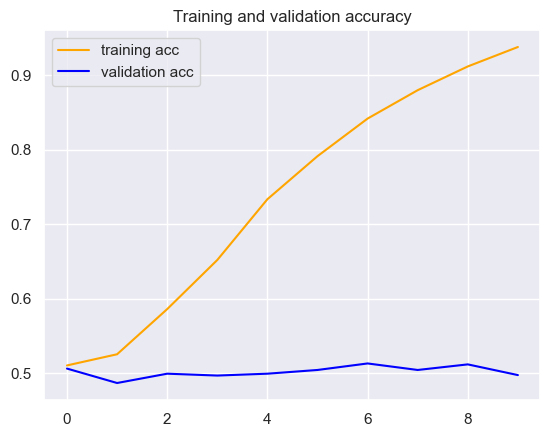

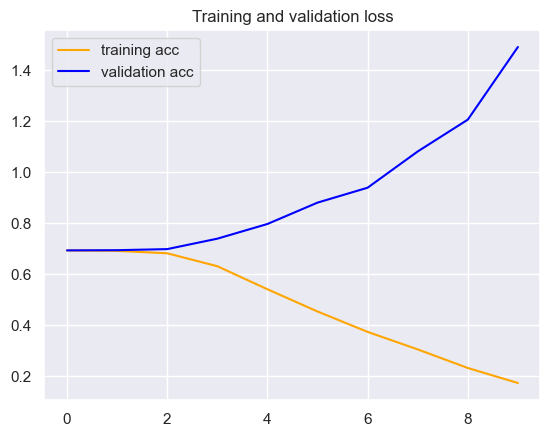

In [ ]:
acc = history_ltsm.history['acc']
val_acc = history_ltsm.history['val_acc']
loss = history_ltsm.history['loss']
val_loss = history_ltsm.history['val_loss']
epochs = range(len(acc))
plt.plot(epochs, acc, '-', color='orange', label='training acc')
plt.plot(epochs, val_acc, '-', color='blue', label='validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.show()

plt.plot(epochs, loss, '-', color='orange', label='training acc')
plt.plot(epochs, val_loss,  '-', color='blue', label='validation acc')
plt.title('Training and validation loss')
plt.legend()
plt.show()